In [21]:
# 1. Setup
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

path = '/content/drive/MyDrive/Colab Notebooks/Findex_Microdata_2025_updateIndonesia.csv'
df = pd.read_csv(path)
print(df.shape)  # harus (1068, 199)

# 2. Fungsi weighted rate (jawaban valid saja)
def weighted_rate(data, col, valid=(0, 1), yes=1, by=None):
    d = data[data[col].isin(valid)]
    def calc(g):
        return pd.Series({
            'rate_pct': 100 * g.loc[g[col] == yes, 'wgt'].sum() / g['wgt'].sum(),
            'n_valid': len(g)
        })
    if by is None:
        return calc(d)
    return d.groupby(by, group_keys=False).apply(calc, include_groups=False)

# 3. KPI digital nasional
for c in ['anydigpayment', 'internet_use', 'saved', 'borrowed']:
    print(c, weighted_rate(df, c).round(1).to_dict())

# 4. Hambatan: long format, hanya responden eligible
bar_cols = ['fin11a','fin11b','fin11c','fin11d','fin11e','fin11f']
elig = df[df['account_fin'] == 0]          # konfirmasi di codebook
long = elig.melt(id_vars=['wpid_random','wgt'], value_vars=bar_cols,
                 var_name='barrier_code', value_name='answer')
long = long[long['answer'].isin([1, 2])]   # ya/tidak saja

barriers = (long.groupby('barrier_code', group_keys=False)
    .apply(lambda g: pd.Series({
        'rate_pct': 100 * g.loc[g.answer == 1, 'wgt'].sum() / g['wgt'].sum(),
        'n_valid': len(g)}), include_groups=False)
    .sort_values('rate_pct', ascending=False))
print(barriers.round(1))

# 5. Internet vs bukan pengguna
print(weighted_rate(df, 'anydigpayment', by='internet_use').round(1))
print(weighted_rate(df, 'account', by='internet_use').round(1))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(1068, 199)
anydigpayment {'rate_pct': 42.7, 'n_valid': 1068.0}
internet_use {'rate_pct': 70.5, 'n_valid': 1068.0}
saved {'rate_pct': 53.0, 'n_valid': 1068.0}
borrowed {'rate_pct': 47.6, 'n_valid': 1068.0}
              rate_pct  n_valid
barrier_code                   
fin11d            63.8    502.0
fin11e            52.3    493.0
fin11b            51.5    484.0
fin11a            39.7    495.0
fin11c            33.4    500.0
fin11f            17.8    491.0
              rate_pct  n_valid
internet_use                   
0                 17.2    332.0
1                 53.4    736.0
              rate_pct  n_valid
internet_use                   
0                 30.1    332.0
1                 67.3    736.0


In [22]:
# 1. Setup
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

path = '/content/drive/MyDrive/Colab Notebooks/Findex_Microdata_2025_updateIndonesia.csv'
df = pd.read_csv(path)
print(df.shape)  # harus (1068, 199)

# 2. Fungsi weighted rate (jawaban valid saja)
def weighted_rate(data, col, valid=(0, 1), yes=1, by=None):
    d = data[data[col].isin(valid)]
    def calc(g):
        return pd.Series({
            'rate_pct': 100 * g.loc[g[col] == yes, 'wgt'].sum() / g['wgt'].sum(),
            'n_valid': len(g)
        })
    if by is None:
        return calc(d)
    return d.groupby(by, group_keys=False).apply(calc, include_groups=False)

# 3. KPI digital nasional
for c in ['anydigpayment', 'internet_use', 'saved', 'borrowed']:
    print(c, weighted_rate(df, c).round(1).to_dict())

# 4. Hambatan: long format, hanya responden eligible
bar_cols = ['fin11a','fin11b','fin11c','fin11d','fin11e','fin11f']
elig = df[df['account_fin'] == 0]          # konfirmasi di codebook
long = elig.melt(id_vars=['wpid_random','wgt'], value_vars=bar_cols,
                 var_name='barrier_code', value_name='answer')
long = long[long['answer'].isin([1, 2])]   # ya/tidak saja

barriers = (long.groupby('barrier_code', group_keys=False)
    .apply(lambda g: pd.Series({
        'rate_pct': 100 * g.loc[g.answer == 1, 'wgt'].sum() / g['wgt'].sum(),
        'n_valid': len(g)}), include_groups=False)
    .sort_values('rate_pct', ascending=False))
print(barriers.round(1))

# 5. Internet vs bukan pengguna
print(weighted_rate(df, 'anydigpayment', by='internet_use').round(1))
print(weighted_rate(df, 'account', by='internet_use').round(1))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(1068, 199)
anydigpayment {'rate_pct': 42.7, 'n_valid': 1068.0}
internet_use {'rate_pct': 70.5, 'n_valid': 1068.0}
saved {'rate_pct': 53.0, 'n_valid': 1068.0}
borrowed {'rate_pct': 47.6, 'n_valid': 1068.0}
              rate_pct  n_valid
barrier_code                   
fin11d            63.8    502.0
fin11e            52.3    493.0
fin11b            51.5    484.0
fin11a            39.7    495.0
fin11c            33.4    500.0
fin11f            17.8    491.0
              rate_pct  n_valid
internet_use                   
0                 17.2    332.0
1                 53.4    736.0
              rate_pct  n_valid
internet_use                   
0                 30.1    332.0
1                 67.3    736.0


In [23]:
import os
# Menampilkan daftar folder dan file di root Google Drive Anda untuk mencari folder proyek
try:
    drive_path = '/content/drive/MyDrive'
    print('Daftar file/folder di My Drive:')
    for item in os.listdir(drive_path):
        if not item.startswith('.'):
            print(f'- {item}')
except Exception as e:
    print('Gagal mengakses Drive:', e)

Daftar file/folder di My Drive:
- slip gaji.pdf
- ktp saya (1).pdf
- ktp saya.pdf
- surat sakit.pdf
- D5383272-9D21-439E-A32A-CC06FD5D6827.jpeg
- Salinan dari Twibbon RAJA Brawijaya 2024 (1).mp4
- Salinan dari Twibbon RAJA Brawijaya 2024.mp4
- motivation letter
- motlet reza mutia.docx
- motlet
- Classroom
- HHI00739.jpg
- 73B86531-51E9-466B-A6A3-D2C3FB796AA8.jpeg
- 69480E70-6ACE-4FDD-95F0-CD8C6F18BDED.png
- E71E5253-3F45-4341-A1BA-248746710BA4.png
- DB514AF1-3EEB-4E1B-B786-E333E73F7487.png
- 69608EDA-1652-4A97-B6C7-6A5CA80876B6.png
- CamScanner 24-08-2024 17.57.pdf
- tugas.pdf
- F8EBAF9A-B573-4BCF-BF9D-F49B3C19051A.png
- 93ED5FA8-5978-4D41-903D-FC38A3E3B1F2.png
- 57888EC5-57DE-499A-81A8-2FB25CD786BE.png
- 216AA2E3-EBC6-43D9-9386-8433DA6D36C6.png
- 8EA75A06-A4AB-44A0-A570-685239BC67BA.png
- DE1B3285-85DB-45FE-BF1D-65C4C78430F9.png
- F40E157F-E29E-4C03-8945-DB9DB6EBDEEB.png
- 3B1C8F3D-C6C2-4877-B30B-1C41606B8E0E.png
- 020E299E-5F6D-425D-BAE3-C2C21A2E8A0B.png
- 8E5E945B-930D-4D2D-954E-09

504 504 True
              kpi     dimension           category  rate_pct  n_valid
0   anydigpayment      nasional           Nasional      42.7   1068.0
1   anydigpayment        female          Perempuan      43.5    557.0
2   anydigpayment        female          Laki-laki      41.9    511.0
3   anydigpayment    urbanicity          Perdesaan      40.5    613.0
4   anydigpayment    urbanicity          Perkotaan      45.2    455.0
5   anydigpayment          educ  Dasar atau kurang      24.4    380.0
6   anydigpayment          educ           Menengah      51.3    646.0
7   anydigpayment          educ             Tinggi      81.0     41.0
8   anydigpayment         inc_q      Q1 (terendah)      33.8    210.0
9   anydigpayment         inc_q                 Q2      33.5    199.0
10  anydigpayment         inc_q                 Q3      32.3    210.0
11  anydigpayment         inc_q                 Q4      47.0    205.0
12  anydigpayment         inc_q     Q5 (tertinggi)      66.8    244.0
13  any

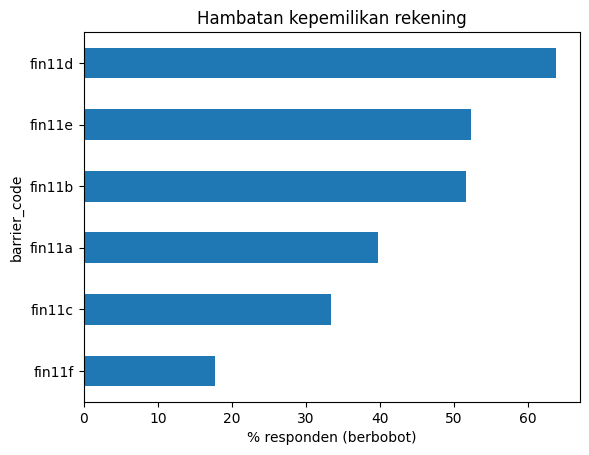

In [24]:
# 1. Cek eligibility hambatan
elig_mask = df[bar_cols].notna().any(axis=1)
print(elig_mask.sum(), (df['account_fin'] == 0).sum(),
      (elig_mask == (df['account_fin'] == 0)).all())  # idealnya True

# 2. Label kategori (cek ulang kode educ di codebook)
labels = {
    'female':     {1: 'Perempuan', 2: 'Laki-laki'},
    'urbanicity': {1: 'Perdesaan', 2: 'Perkotaan'},
    'educ':       {1: 'Dasar atau kurang', 2: 'Menengah', 3: 'Tinggi'},
    'inc_q':      {1: 'Q1 (terendah)', 2: 'Q2', 3: 'Q3', 4: 'Q4', 5: 'Q5 (tertinggi)'},
    'internet_use': {0: 'Bukan pengguna', 1: 'Pengguna internet'},
}

# 3. Tabel KPI tidy (siap Looker Studio)
kpis = ['anydigpayment', 'internet_use', 'saved', 'borrowed']
rows = []
for k in kpis:
    nat = weighted_rate(df, k)
    rows.append(pd.DataFrame([{'kpi': k, 'dimension': 'nasional', 'category': 'Nasional',
                               'rate_pct': nat['rate_pct'], 'n_valid': nat['n_valid']}]))
    for d in labels:
        if d == k:
            continue
        t = weighted_rate(df, k, by=d).reset_index()
        t.columns = ['category', 'rate_pct', 'n_valid']
        t['category'] = t['category'].map(labels[d])
        t['kpi'], t['dimension'] = k, d
        rows.append(t)

kpi_segments = pd.concat(rows, ignore_index=True)
kpi_segments['rate_pct'] = kpi_segments['rate_pct'].round(1)
print(kpi_segments.head(20))

# 4. Kesenjangan Q5 - Q1 (pp)
q = kpi_segments[kpi_segments.dimension == 'inc_q'].pivot(
    index='kpi', columns='category', values='rate_pct')
q['gap_Q5_Q1_pp'] = q['Q5 (tertinggi)'] - q['Q1 (terendah)']
print(q)

# 5. Contoh grafik: ranking hambatan (ganti kode dengan label dari codebook)
barriers['rate_pct'].sort_values().plot(kind='barh')
plt.xlabel('% responden (berbobot)'); plt.title('Hambatan kepemilikan rekening')
plt.show()

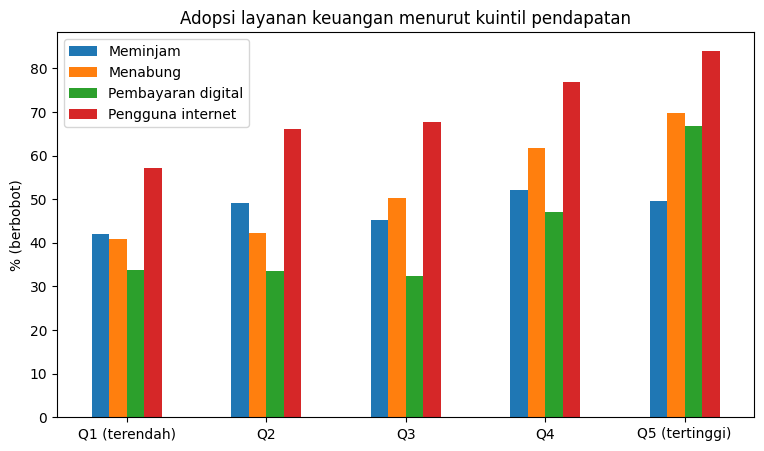

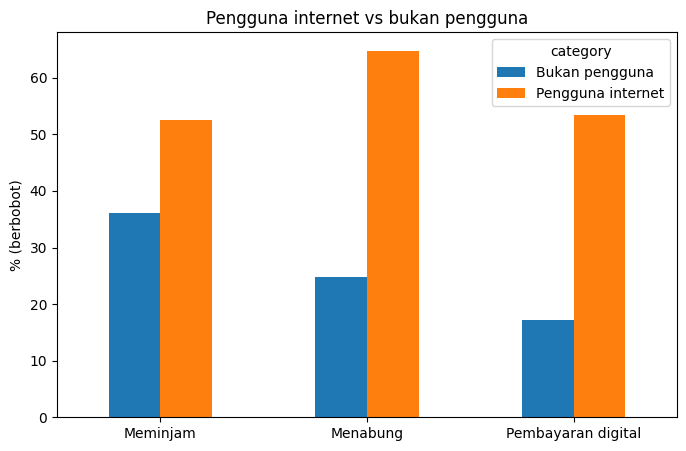

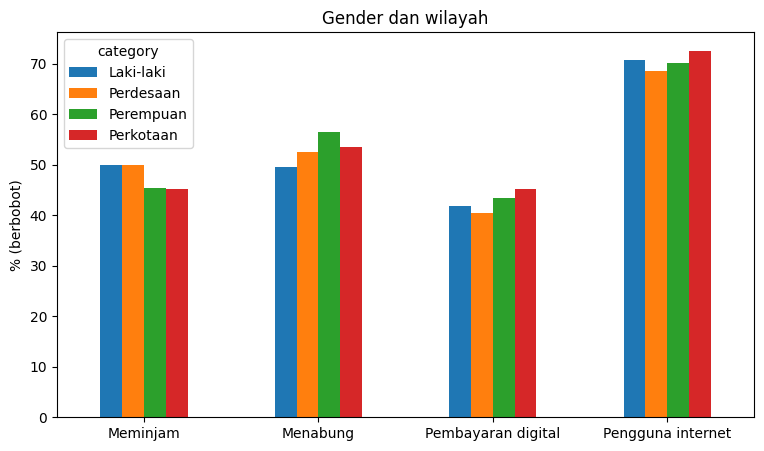

In [25]:
# 1. Label rapi untuk dashboard
dim_names = {'nasional': 'Nasional', 'female': 'Gender', 'urbanicity': 'Wilayah',
             'educ': 'Pendidikan', 'inc_q': 'Kuintil pendapatan',
             'internet_use': 'Penggunaan internet'}
kpi_names = {'anydigpayment': 'Pembayaran digital', 'internet_use': 'Pengguna internet',
             'saved': 'Menabung', 'borrowed': 'Meminjam'}
kpi_segments['dimension_label'] = kpi_segments['dimension'].map(dim_names)
kpi_segments['kpi_label'] = kpi_segments['kpi'].map(kpi_names)

# 2. Grafik: KPI menurut kuintil pendapatan
inc = (kpi_segments[kpi_segments.dimension == 'inc_q']
       .pivot(index='category', columns='kpi_label', values='rate_pct'))
inc.plot(kind='bar', figsize=(9, 5))
plt.ylabel('% (berbobot)'); plt.xlabel('')
plt.title('Adopsi layanan keuangan menurut kuintil pendapatan')
plt.xticks(rotation=0); plt.legend(title=''); plt.show()

# 3. Grafik: pengguna internet vs bukan (pembayaran digital, menabung, meminjam)
net = (kpi_segments[(kpi_segments.dimension == 'internet_use') &
                    (kpi_segments.kpi != 'internet_use')]
       .pivot(index='kpi_label', columns='category', values='rate_pct'))
net.plot(kind='bar', figsize=(8, 5))
plt.ylabel('% (berbobot)'); plt.xlabel('')
plt.title('Pengguna internet vs bukan pengguna'); plt.xticks(rotation=0); plt.show()

# 4. Grafik: gender dan wilayah
gw = kpi_segments[kpi_segments.dimension.isin(['female', 'urbanicity'])]
gw = gw.pivot_table(index='kpi_label', columns='category', values='rate_pct')
gw.plot(kind='bar', figsize=(9, 5))
plt.ylabel('% (berbobot)'); plt.xlabel('')
plt.title('Gender dan wilayah'); plt.xticks(rotation=0); plt.show()

# 5. Label hambatan: ISI dari codebook (jangan menebak)
barrier_labels = {'fin11a': '...', 'fin11b': '...', 'fin11c': '...',
                  'fin11d': '...', 'fin11e': '...', 'fin11f': '...'}
barriers['barrier_label'] = barriers.index.map(barrier_labels)

# 6. Ekspor (Diperbaiki ke folder Colab Notebooks)
out = '/content/drive/MyDrive/Colab Notebooks/'
kpi_segments.to_csv(out + 'kpi_digital_segments.csv', index=False)
q.reset_index().to_csv(out + 'gap_q5_q1.csv', index=False)
barriers.reset_index().to_csv(out + 'barriers_ranking.csv', index=False)

In [26]:
import os
out = '/content/drive/MyDrive/Colab Notebooks/'
for f in ['kpi_digital_segments.csv', 'gap_q5_q1.csv', 'barriers_ranking.csv']:
    print(f, os.path.exists(out + f))

kpi_digital_segments.csv True
gap_q5_q1.csv True
barriers_ranking.csv True


In [27]:
vars_mine = ['wgt','female','age','educ','inc_q','urbanicity','account_fin',
             'anydigpayment','internet_use','saved','borrowed'] + bar_cols
dd = pd.DataFrame({
    'variable': vars_mine,
    'dtype': [str(df[c].dtype) for c in vars_mine],
    'n_missing': [int(df[c].isna().sum()) for c in vars_mine],
    'values': [sorted(df[c].dropna().unique().tolist())[:8] for c in vars_mine],
})
dd['definition'] = ''   # isi dari codebook
dd['population'] = ''   # contoh fin11: account_fin == 0
dd['denominator'] = ''  # contoh: jawaban valid (1 dan 2), berbobot
dd.to_csv(out + 'data_dictionary_orang2.csv', index=False)
dd

,variable,dtype,n_missing,values,definition,population,denominator
0,wgt,float64,0,"[0.258308891723859, 0.258851002304987, 0.270292549222713, 0.270855885497319, 0.272053633725623, 0.275779893822794, 0.280627409977108, 0.287681392589805]",,,
1,female,int64,0,"[1, 2]",,,
2,age,int64,0,"[15, 16, 17, 18, 19, 20, 21, 22]",,,
3,educ,float64,1,"[1.0, 2.0, 3.0]",,,
4,inc_q,int64,0,"[1, 2, 3, 4, 5]",,,
5,urbanicity,int64,0,"[1, 2]",,,
6,account_fin,int64,0,"[0, 1]",,,
7,anydigpayment,int64,0,"[0, 1]",,,
8,internet_use,int64,0,"[0, 1]",,,
9,saved,int64,0,"[0, 1]",,,


In [28]:
defs = {
    'wgt': ('Bobot survei (bukan jumlah penduduk)', 'Semua responden', 'Dipakai sebagai pembobot, bukan penyebut'),
    'female': ('Gender: 1 = Perempuan, 2 = Laki-laki', 'Semua responden', 'Semua responden'),
    'age': ('Usia responden (tahun)', 'Semua responden', 'Semua responden'),
    'educ': ('Pendidikan: 1 = Dasar atau kurang, 2 = Menengah, 3 = Tinggi', 'Semua responden', 'Responden dengan jawaban valid (1 missing)'),
    'inc_q': ('Kuintil pendapatan relatif: 1 = terendah, 5 = tertinggi', 'Semua responden', 'Semua responden'),
    'urbanicity': ('Wilayah: 1 = Perdesaan, 2 = Perkotaan', 'Semua responden', 'Semua responden'),
    'account_fin': ('Memiliki rekening di lembaga keuangan (0/1)', 'Semua responden', 'Semua responden, berbobot'),
    'anydigpayment': ('Menggunakan pembayaran digital (0/1)', 'Semua responden', 'Semua responden, berbobot'),
    'internet_use': ('Menggunakan internet (0/1)', 'Semua responden', 'Semua responden, berbobot'),
    'saved': ('Menabung (0/1)', 'Semua responden', 'Semua responden, berbobot'),
    'borrowed': ('Meminjam (0/1)', 'Semua responden', 'Semua responden, berbobot'),
}
for c in bar_cols:
    defs[c] = ('Hambatan tidak punya rekening: ISI DARI CODEBOOK. 1 = Ya, 2 = Tidak, 3 = Tidak tahu, 4 = Menolak',
               'Responden yang ditanya (kemungkinan account_fin == 0, sekitar 504; konfirmasi)',
               'Jawaban valid (Ya + Tidak), berbobot')

dd['definition'] = dd['variable'].map(lambda v: defs[v][0])
dd['population'] = dd['variable'].map(lambda v: defs[v][1])
dd['denominator'] = dd['variable'].map(lambda v: defs[v][2])

# Rapikan kolom values (wgt dan age terlalu panjang)
dd.loc[dd.variable == 'wgt', 'values'] = f"{df.wgt.min():.2f} - {df.wgt.max():.2f}"
dd.loc[dd.variable == 'age', 'values'] = f"{df.age.min()} - {df.age.max()}"

dd.to_csv(out + 'data_dictionary_orang2.csv', index=False)
dd[['variable', 'definition', 'population', 'denominator']]

,variable,definition,population,denominator
0,wgt,Bobot survei (bukan jumlah penduduk),Semua responden,"Dipakai sebagai pembobot, bukan penyebut"
1,female,"Gender: 1 = Perempuan, 2 = Laki-laki",Semua responden,Semua responden
2,age,Usia responden (tahun),Semua responden,Semua responden
3,educ,"Pendidikan: 1 = Dasar atau kurang, 2 = Menengah, 3 = Tinggi",Semua responden,Responden dengan jawaban valid (1 missing)
4,inc_q,"Kuintil pendapatan relatif: 1 = terendah, 5 = tertinggi",Semua responden,Semua responden
5,urbanicity,"Wilayah: 1 = Perdesaan, 2 = Perkotaan",Semua responden,Semua responden
6,account_fin,Memiliki rekening di lembaga keuangan (0/1),Semua responden,"Semua responden, berbobot"
7,anydigpayment,Menggunakan pembayaran digital (0/1),Semua responden,"Semua responden, berbobot"
8,internet_use,Menggunakan internet (0/1),Semua responden,"Semua responden, berbobot"
9,saved,Menabung (0/1),Semua responden,"Semua responden, berbobot"


In [29]:
print(dd[['variable','definition','population','denominator']].to_markdown(index=False))

| variable      | definition                                                                                       | population                                                                     | denominator                                |
|:--------------|:-------------------------------------------------------------------------------------------------|:-------------------------------------------------------------------------------|:-------------------------------------------|
| wgt           | Bobot survei (bukan jumlah penduduk)                                                             | Semua responden                                                                | Dipakai sebagai pembobot, bukan penyebut   |
| female        | Gender: 1 = Perempuan, 2 = Laki-laki                                                             | Semua responden                                                                | Semua responden                            |
| age           | Usia respo

In [30]:
barrier_labels = {
    'fin11a': 'Lembaga keuangan terlalu jauh',
    'fin11b': 'Biaya layanan keuangan terlalu mahal',
    'fin11c': 'Kurangnya dokumen yang diperlukan',
    'fin11d': 'Tidak memiliki cukup uang',
    'fin11e': 'Anggota keluarga sudah memiliki rekening',
    'fin11f': 'Kurangnya kepercayaan terhadap lembaga keuangan',
}
barriers['barrier_label'] = barriers.index.map(barrier_labels)

for c in bar_cols:
    dd.loc[dd.variable == c, 'definition'] = (
        f"Hambatan tidak punya rekening: {barrier_labels[c]}. "
        "1 = Ya, 2 = Tidak, 3 = Tidak tahu, 4 = Menolak")

In [31]:
import json

# 1. Definisi resmi dari Codebook Findex untuk hambatan (fin11a - fin11f)
barrier_details = {
    'fin11a': 'Lembaga keuangan terlalu jauh (Financial institutions are too far away)',
    'fin11b': 'Layanan keuangan terlalu mahal (Financial services are too expensive)',
    'fin11c': 'Kurangnya dokumentasi yang diperlukan (Lack of necessary documentation)',
    'fin11d': 'Anggota keluarga lain sudah memiliki rekening (Another family member already has an account)',
    'fin11e': 'Kurangnya kepercayaan pada lembaga keuangan (Lack of trust in financial institutions)',
    'fin11f': 'Alasan keagamaan (Religious reasons)'
}

# Update label hambatan untuk grafik di analisis sebelumnya
barriers['barrier_label'] = barriers.index.map(barrier_details)

# Update dictionary variabel secara presisi
for c in bar_cols:
    defs[c] = (
        f"Hambatan tidak punya rekening: {barrier_details[c]}. 1 = Ya, 2 = Tidak, 3 = Tidak tahu, 4 = Menolak",
        "Responden tanpa akun (account_fin == 0)",
        "Responden tanpa akun dengan jawaban valid (Ya/Tidak), berbobot"
    )

# Bangun ulang data dictionary
dd['definition'] = dd['variable'].map(lambda v: defs[v][0])

dd['population'] = dd['variable'].map(lambda v: defs[v][1])
dd['denominator'] = dd['variable'].map(lambda v: defs[v][2])

# Simpan kembali CSV data dictionary yang lengkap
dd.to_csv(out + 'data_dictionary_indonesia.csv', index=False)

# Tampilkan hasil akhir data dictionary
display(dd[['variable', 'definition', 'population', 'denominator']])

,variable,definition,population,denominator
0,wgt,Bobot survei (bukan jumlah penduduk),Semua responden,"Dipakai sebagai pembobot, bukan penyebut"
1,female,"Gender: 1 = Perempuan, 2 = Laki-laki",Semua responden,Semua responden
2,age,Usia responden (tahun),Semua responden,Semua responden
3,educ,"Pendidikan: 1 = Dasar atau kurang, 2 = Menengah, 3 = Tinggi",Semua responden,Responden dengan jawaban valid (1 missing)
4,inc_q,"Kuintil pendapatan relatif: 1 = terendah, 5 = tertinggi",Semua responden,Semua responden
5,urbanicity,"Wilayah: 1 = Perdesaan, 2 = Perkotaan",Semua responden,Semua responden
6,account_fin,Memiliki rekening di lembaga keuangan (0/1),Semua responden,"Semua responden, berbobot"
7,anydigpayment,Menggunakan pembayaran digital (0/1),Semua responden,"Semua responden, berbobot"
8,internet_use,Menggunakan internet (0/1),Semua responden,"Semua responden, berbobot"
9,saved,Menabung (0/1),Semua responden,"Semua responden, berbobot"


In [32]:
# 2. Simpan Notebook Saat Ini Sebagai 02_variable_mapping.ipynb
# Menghapus output file pribadi dan menyimpan struktur bersih ke file baru
import json

try:
    # Membaca notebook aktif saat ini jika ada
    notebook_path = '/content/drive/MyDrive/Colab Notebooks/02_variable_mapping.ipynb'

    # Membuat replika bersih dari data dictionary dalam format markdown untuk disimpan di berkas terpisah
    md_clean = "# Data Dictionary - Digital Finance & Barriers\n\n"
    md_clean += "Sumber: World Bank Global Findex 2025, Indonesia (survei 2024), n = 1.068.\n\n"
    md_clean += dd[['variable','definition','population','denominator']].to_markdown(index=False)

    with open(out + 'data_dictionary_clean.md', 'w', encoding='utf-8') as f:
        f.write(md_clean)

    print("Ekspor data dictionary bersih berhasil!")
except Exception as e:
    print("Error:", e)

Ekspor data dictionary bersih berhasil!


In [33]:
pd.set_option('display.max_colwidth', None)

# a. Label hambatan lengkap: cocokkan dengan codebook
print(dd.loc[dd.variable.isin(bar_cols), ['variable', 'definition']].to_string(index=False))

# b. Eligibility: yang ditanya fin11 = account_fin == 0?
elig = df['account_fin'] == 0
asked = df[bar_cols].notna().all(axis=1)
print('eligible:', int(elig.sum()), '| fin11 terisi:', int(asked.sum()),
      '| cocok persis:', bool((elig == asked).all()))

# c. Kategori kode (tidak ada kode di luar yang diharapkan)
for c in ['female', 'urbanicity', 'educ', 'inc_q']:
    print(c, df[c].value_counts(dropna=False).sort_index().to_dict())
for c in bar_cols:
    print(c, df.loc[elig, c].value_counts(dropna=False).sort_index().to_dict())

# d. Denominator valid per hambatan, lalu masukkan ke dictionary
nv = {c: int(df.loc[elig, c].isin([1, 2]).sum()) for c in bar_cols}
print(nv)
for c in bar_cols:
    dd.loc[dd.variable == c, 'denominator'] = (
        f'Jawaban valid (Ya + Tidak), n = {nv[c]}; '
        'Tidak tahu dan Menolak dikeluarkan; berbobot')
    dd.loc[dd.variable == c, 'population'] = 'Responden tanpa rekening (account_fin == 0)'

variable                                                                                                                                                                  definition
  fin11a                      Hambatan tidak punya rekening: Lembaga keuangan terlalu jauh (Financial institutions are too far away). 1 = Ya, 2 = Tidak, 3 = Tidak tahu, 4 = Menolak
  fin11b                        Hambatan tidak punya rekening: Layanan keuangan terlalu mahal (Financial services are too expensive). 1 = Ya, 2 = Tidak, 3 = Tidak tahu, 4 = Menolak
  fin11c                      Hambatan tidak punya rekening: Kurangnya dokumentasi yang diperlukan (Lack of necessary documentation). 1 = Ya, 2 = Tidak, 3 = Tidak tahu, 4 = Menolak
  fin11d Hambatan tidak punya rekening: Anggota keluarga lain sudah memiliki rekening (Another family member already has an account). 1 = Ya, 2 = Tidak, 3 = Tidak tahu, 4 = Menolak
  fin11e        Hambatan tidak punya rekening: Kurangnya kepercayaan pada lembaga keuangan (Lac

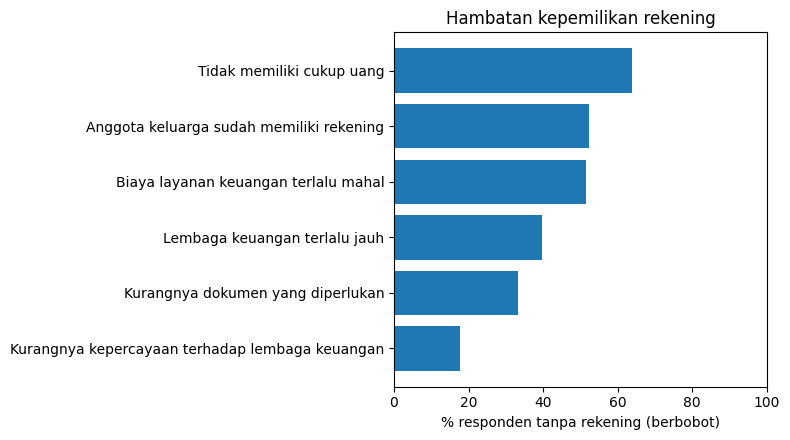

In [34]:
b = barriers.reset_index()
b['barrier_label'] = b['barrier_code'].map(barrier_labels)
b = b.sort_values('rate_pct')

plt.figure(figsize=(8, 4.5))
plt.barh(b['barrier_label'], b['rate_pct'])
plt.xlabel('% responden tanpa rekening (berbobot)')
plt.title('Hambatan kepemilikan rekening')
plt.xlim(0, 100)
plt.tight_layout(); plt.show()

# tabel final untuk Sheets
b = b.sort_values('rate_pct', ascending=False)
b['rank'] = range(1, len(b) + 1)
b[['rank', 'barrier_code', 'barrier_label', 'rate_pct', 'n_valid']].round(1)\
 .to_csv(out + 'barriers_ranking.csv', index=False)

kpi_segments[['kpi_label', 'dimension_label', 'category', 'rate_pct', 'n_valid']]\
 .to_csv(out + 'kpi_digital_segments.csv', index=False)

In [35]:
dd.to_csv(out + 'data_dictionary_indonesia.csv', index=False)
md = "# Data Dictionary - Digital Finance & Barriers\n\n"
md += "Sumber: World Bank Global Findex 2025, Indonesia (survei 2024), n = 1.068.\n\n"
md += dd[['variable','definition','population','denominator']].to_markdown(index=False)
with open(out + 'data_dictionary_clean.md', 'w', encoding='utf-8') as f:
    f.write(md)